In [92]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from mord import LogisticAT  # Ordinal logistic regression
from sklearn.metrics import classification_report, confusion_matrix
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import tensorflow_addons as tfa
from keras import backend as K
from keras import losses

%config Completer.use_jedi = False

In [93]:
r = pd.read_csv("Blendshapes_Summary_1800_100.csv", index_col=0)
print(r.shape)
r.head()

(29708, 222)


,slice_index,filename,start_frame,end_frame,_neutral_mean,browDownLeft_mean,browDownRight_mean,browInnerUp_mean,browOuterUpLeft_mean,browOuterUpRight_mean,...,blinks_count,blinks_mean_duration,blinks_std_duration,blinks_min_duration,blinks_max_duration,yawns_count,yawns_mean_duration,yawns_std_duration,yawns_min_duration,yawns_max_duration
0,0,2_21_10_30fps_blendshape.csv,0,1799,0.0,0.020961,0.011672,0.091767,0.175344,0.169944,...,38,5.394737,2.604979,1,14,0,0.0,0.0,0,0
1,1,2_21_10_30fps_blendshape.csv,100,1899,0.0,0.023722,0.013317,0.084261,0.166261,0.161839,...,38,5.026316,2.259955,1,14,0,0.0,0.0,0,0
2,2,2_21_10_30fps_blendshape.csv,200,1999,0.0,0.024122,0.013600,0.087417,0.166378,0.161378,...,39,4.923077,2.309985,1,14,0,0.0,0.0,0,0
3,3,2_21_10_30fps_blendshape.csv,300,2099,0.0,0.024967,0.013989,0.085200,0.162722,0.157400,...,37,4.810811,2.132263,1,14,0,0.0,0.0,0,0
4,4,2_21_10_30fps_blendshape.csv,400,2199,0.0,0.026233,0.014633,0.082817,0.159100,0.153994,...,39,4.769231,2.070616,1,14,0,0.0,0.0,0,0


In [94]:
r['target'] = r['filename'].apply(lambda x:int(x.split('_')[2].replace('10','1').replace('0','-1').replace('5','0')))
r['target'].value_counts()

 1    10416
 0     9782
-1     9510
Name: target, dtype: int64

In [95]:
r['filename'].apply(lambda x: x.split('_')[0]).value_counts()

5    6410
3    6378
2    6114
1    5838
4    4968
Name: filename, dtype: int64

In [96]:
r['fold'] = r['filename'].apply(lambda x: int(x.split('_')[0]))

In [97]:
r['subject_id'] = r['filename'].apply(lambda x: int(x.split('_')[1]))

In [98]:
# def loss(y_true, y_pred):
#     weights = K.cast(K.abs(K.argmax(y_true, axis=1) - K.argmax(y_pred, axis=1))/(K.int_shape(y_pred)[1] - 1), dtype='float32')
#     return (1.0 + weights) * losses.categorical_crossentropy(y_true, y_pred)

# def report(model, x, y):
#     y_pred = model.predict(x, verbose=0)
#     print(classification_report(y.argmax(axis=1), list(y_pred.argmax(axis=1))))
#     print(confusion_matrix(y.argmax(axis=1), list(y_pred.argmax(axis=1))))

def step(val, steps, outputs):
    for i in range(len(steps)-1):
        low = steps[i]
        high = steps[i+1]
        if val >= low and val <= high:
            return outputs[i]
        
def report(model, x, y):
    y_pred = [step(v,[-1.5,-0.5,0.5,1.5],[-1,0,1]) for v in model.predict(x, verbose=0)]
    print(classification_report(list(y), y_pred))
    print(confusion_matrix(list(y), y_pred))

Test : 1   Validation : 2
train dataset dimension (17756, 218)
validation dataset dimension (6114, 218)
test dataset dimension (5838, 218)
Epoch 1/200
278/278 [==============================] - 1s 1ms/step - loss: 1.4989 - accuracy: 0.4087 - val_loss: 1.2950 - val_accuracy: 0.4681
Epoch 2/200
278/278 [==============================] - 0s 976us/step - loss: 0.8975 - accuracy: 0.4496 - val_loss: 1.0636 - val_accuracy: 0.4565
Epoch 3/200
278/278 [==============================] - 0s 944us/step - loss: 0.6371 - accuracy: 0.4739 - val_loss: 0.9321 - val_accuracy: 0.4457
Epoch 4/200
278/278 [==============================] - 0s 968us/step - loss: 0.4887 - accuracy: 0.4976 - val_loss: 0.8967 - val_accuracy: 0.4658
Epoch 5/200
278/278 [==============================] - 0s 964us/step - loss: 0.3945 - accuracy: 0.5177 - val_loss: 0.7953 - val_accuracy: 0.4398
Epoch 6/200
278/278 [==============================] - 0s 950us/step - loss: 0.3382 - accuracy: 0.5312 - val_loss: 0.8377 - val_accuracy: 

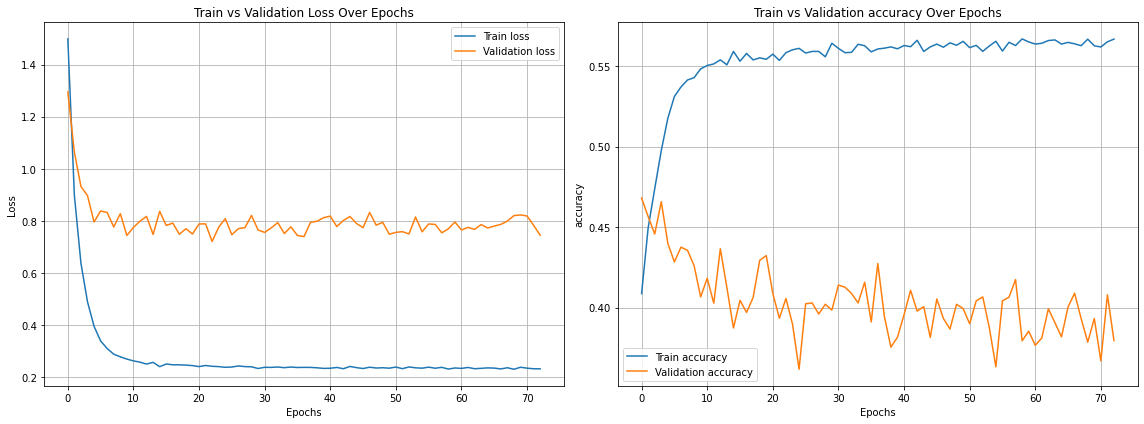

              precision    recall  f1-score   support

          -1       0.97      0.82      0.89      5540
           0       0.74      0.96      0.83      5792
           1       0.98      0.84      0.91      6424

    accuracy                           0.88     17756
   macro avg       0.90      0.88      0.88     17756
weighted avg       0.90      0.88      0.88     17756

[[4560  980    0]
 [ 119 5572  101]
 [   1 1004 5419]]
              precision    recall  f1-score   support

          -1       0.91      0.69      0.78      7533
           0       0.63      0.87      0.73      7836
           1       0.87      0.75      0.81      8501

    accuracy                           0.77     23870
   macro avg       0.80      0.77      0.78     23870
weighted avg       0.80      0.77      0.78     23870

[[5187 2029  317]
 [ 345 6833  658]
 [ 154 1935 6412]]
              precision    recall  f1-score   support

          -1       0.42      0.50      0.46      1977
           0       

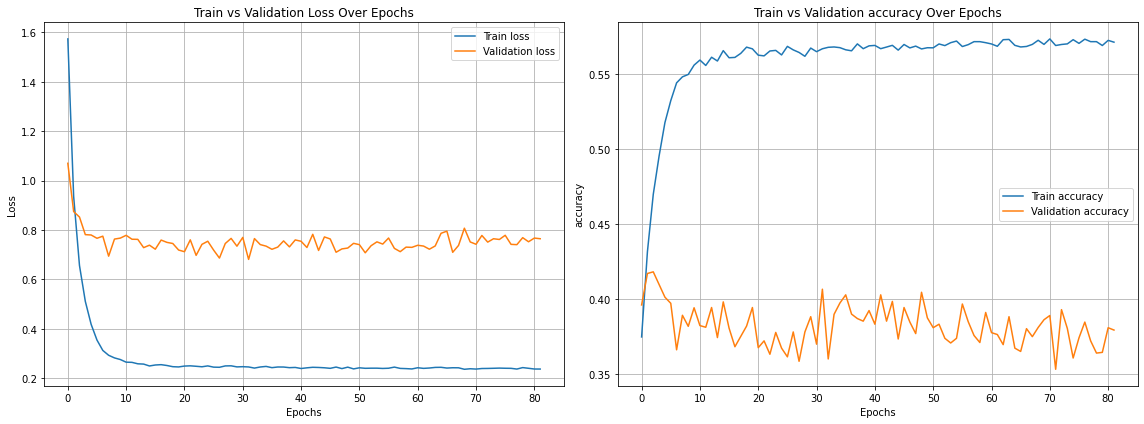

              precision    recall  f1-score   support

          -1       0.98      0.83      0.90      5353
           0       0.73      0.97      0.83      5663
           1       0.99      0.83      0.90      6476

    accuracy                           0.88     17492
   macro avg       0.90      0.88      0.88     17492
weighted avg       0.90      0.88      0.88     17492

[[4466  887    0]
 [ 113 5484   66]
 [   1 1111 5364]]
              precision    recall  f1-score   support

          -1       0.87      0.71      0.79      7533
           0       0.63      0.88      0.74      7836
           1       0.91      0.72      0.81      8501

    accuracy                           0.77     23870
   macro avg       0.81      0.77      0.78     23870
weighted avg       0.81      0.77      0.78     23870

[[5386 1987  160]
 [ 496 6915  425]
 [ 287 2071 6143]]
              precision    recall  f1-score   support

          -1       0.46      0.56      0.50      1977
           0       

In [106]:
# num_layers = 6
# num_units = 8
units = [10]
dropout_ratio = 0.5
batch_size = 64

# Define the neural network model
def build_model(input_shape, num_classes):
    model = keras.Sequential()
    model.add(layers.Input(shape=(input_shape,)))  # Ensure input shape matches your data

    for u in units:
        model.add(layers.Dense(u, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.)))
        model.add(layers.BatchNormalization())
        model.add(layers.Dropout(dropout_ratio))
    
    # Final output layer
    model.add(layers.Dense(1, activation=lambda x: 3 * tf.keras.activations.sigmoid(x) - 1.5))  

#     model.add(layers.Dense(num_classes, activation='softmax' if num_classes > 1 else 'sigmoid'))

    model.compile(
        optimizer = keras.optimizers.AdamW(
            learning_rate=5e-4,  # Adjust based on your needs
            weight_decay=1e-4,   # Helps prevent overfitting
            beta_1=0.9,          # Default value, controls momentum
            beta_2=0.999,        # Default value, controls adaptive learning
            epsilon=1e-7         # Small constant for numerical stability
        ),
        loss='mse',
        metrics=['accuracy']
    )
    
    return model


for i in range(1,2):
    for j in range(2,4):
        if j == i:
            continue
        print("========================================================================================================================================")
        print(f"Test : {i}   Validation : {j}")

        train = r[r['fold']!=i].reset_index(drop=True)
        test  = r[r['fold']==i].reset_index(drop=True)
        
        val_idx   = list(train[train['fold']==j].index)
        train_idx = list(train[train['fold']!=j].index)
        
        X_train = train.drop(columns=['slice_index', 'filename', 'start_frame', 'end_frame', 'target', 'fold', 'subject_id'])
        y_train = train['target']
#         y_train = keras.utils.to_categorical(train['target'], num_classes=3)

        X_test  = test.drop(columns=['slice_index', 'filename', 'start_frame', 'end_frame', 'target', 'fold', 'subject_id'])
        y_test  = test['target']
#         y_test  = keras.utils.to_categorical(test['target'], num_classes=3)

        scaler         = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled  = scaler.transform(X_test)
        
        X_val = X_train_scaled[val_idx]
        y_val = y_train[val_idx]
        
        X_train_final = X_train_scaled[train_idx]
        y_train_final = y_train[train_idx]
        
        print(f"train dataset dimension {X_train_final.shape}")
        print(f"validation dataset dimension {X_val.shape}")
        print(f"test dataset dimension {X_test_scaled.shape}")

        # Set input and output parameters
        input_shape = 218  # Number of features
        num_classes = 3  # Determine if it's binary or multi-class classification

        # Build and summarize the model
        model = build_model(input_shape, num_classes)
#         print(model.summary())

        # Train the model
        history = model.fit(
            X_train_final, y_train_final,
            validation_data=(X_val, y_val),
            epochs=200,
            batch_size=batch_size,
            callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=50, restore_best_weights=True)],
            verbose=1
        )

        # Create a 1-row, 2-column layout
        plt.figure(figsize=(16, 6))

        # Plot for loss
        plt.subplot(1, 2, 1)  # (rows, columns, index)
        plt.plot(history.history['loss'], label='Train loss')
        plt.plot(history.history['val_loss'], label='Validation loss')
        plt.xlabel('Epochs')
        plt.ylabel('Loss')
        plt.title('Train vs Validation Loss Over Epochs')
        plt.legend()
        plt.grid()

        # Plot for accuracy
        plt.subplot(1, 2, 2)  # (rows, columns, index)
        plt.plot(history.history['accuracy'], label='Train accuracy')
        plt.plot(history.history['val_accuracy'], label='Validation accuracy')
        plt.xlabel('Epochs')
        plt.ylabel('accuracy')
        plt.title('Train vs Validation accuracy Over Epochs')
        plt.legend()
        plt.grid()

        # Show the plots
        plt.tight_layout()
        plt.show()
        
        report(model, X_train_final, y_train_final)
        report(model, X_train_scaled, y_train)
        report(model, X_test_scaled, y_test)
        
        print("========================================================================================================================================\n\n\n")

In [70]:
print(classification_report(y.argmax(axis=1), list(model.predict(x).argmax(axis=1))))
#     print(confusion_matrix(y, list(model.predict(x).argmax(axis=1))))

13/13 [==============================] - 0s 775us/step
              precision    recall  f1-score   support

           0       0.47      0.55      0.51       131
           1       0.33      0.34      0.33       128
           2       0.50      0.40      0.45       127

    accuracy                           0.43       386
   macro avg       0.43      0.43      0.43       386
weighted avg       0.43      0.43      0.43       386



In [44]:
# X = r.drop(columns=['slice_index', 'filename', 'start_frame', 'end_frame', 'target', 'fold'])
# y = r['target']
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
# y_train = keras.utils.to_categorical(y_train, num_classes=3)
# y_test = keras.utils.to_categorical(y_test, num_classes=3)
# scaler = StandardScaler()
# X_train_scaled = scaler.fit_transform(X_train)
# X_test_scaled = scaler.transform(X_test)

In [46]:
# # Set input and output parameters
# input_shape = 218  # Number of features
# num_classes = len(y_train[0])  # Determine if it's binary or multi-class classification

# # Build and summarize the model
# model = build_model(input_shape, num_classes)
# model.summary()

In [47]:
# # Train the model
# history = model.fit(
#     X_train_scaled, y_train,
#     validation_data=(X_test_scaled, y_test),
#     epochs=200,
#     batch_size=32,
#     callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)]
# )

In [49]:
# y_train_pred = model.predict(X_train_scaled)
# y_test_pred = model.predict(X_test_scaled)

In [50]:
# def report(x, y):
#     print(classification_report(y, list(model.predict(x).argmax(axis=1))))
#     print(confusion_matrix(y, list(model.predict(x).argmax(axis=1))))

In [51]:
# list(model.predict(X_train_scaled).argmax(axis=1))

In [115]:
report(X_train_scaled, y_train)

49/49 [==============================] - 0s 757us/step


ValueError: Classification metrics can't handle a mix of multilabel-indicator and multiclass targets

In [79]:
report(X_test_scaled, y_test)

13/13 [==============================] - 0s 762us/step
              precision    recall  f1-score   support

           0       0.87      0.88      0.87       124
           1       0.84      0.81      0.82       129
           2       0.84      0.86      0.85       137

    accuracy                           0.85       390
   macro avg       0.85      0.85      0.85       390
weighted avg       0.85      0.85      0.85       390

13/13 [==============================] - 0s 791us/step
[[109   9   6]
 [  9 104  16]
 [  8  11 118]]


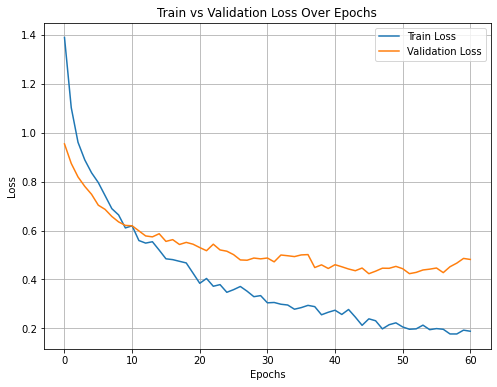

In [80]:
plt.figure(figsize=(8, 6))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Train vs Validation Loss Over Epochs')
plt.legend()
plt.grid()
plt.show()